# 02 · Commodity screener

**Goal:** put seven commodities side by side on the measures that matter to someone trading them: how much they move, where they have been going, how bad the falls get, whether they are trending, whether the calendar matters, and which ones are really the same bet.

Data: the daily panel from notebook 01 (yfinance, with LME 3-month for aluminium) and the World Bank monthly panel for seasonality. The commentary describes data to **30 October 2026**. Re-running updates the numbers but not the text.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=UserWarning)
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import display

from commodities import read_panel
from commodities.config import SHORT_NAMES, TABLES_DIR
from commodities.metrics import (return_correlation, rolling_vol, screener_table, seasonality,
                                 seasonality_table)
from commodities.quality import flag_jumps
from commodities import plots

daily, monthly = read_panel("daily"), read_panel("monthly")
jumps = {c: flag_jumps(daily[c].dropna()).index for c in daily}

## 1. The summary table

| Column | What it is | Why a trader cares |
|---|---|---|
| `vol_1y`, `vol_5y` | Std. dev. of daily log returns × √252 | The "size" of the instrument. Position size should shrink as vol rises, so that each trade risks a similar amount. |
| `vol_1y_ex_jumps` | Same, without the suspected roll jumps from notebook 01 | Shows how much of the headline vol is the continuous-contract artefact |
| `avg_daily_move` | Mean absolute daily % change, last year | The everyday swing you will see on screen; × leverage = swing in your margin |
| `ret_1m` … `ret_5y` | Price change over each window | Momentum at different horizons; disagreement between them is informative |
| `max_dd_5y` | Worst peak-to-trough fall in 5 years | How much pain holding it through a bad patch would have cost |
| `vs_50d`, `vs_200d` | Price vs 50- and 200-day moving average | Short- and long-term trend. **Uptrend** = price > 50d > 200d; **Downtrend** = the reverse; **Mixed** = signals disagree |

In [2]:
table = screener_table(daily, jumps=jumps)
table.index = [SHORT_NAMES[c] for c in table.index]
table.to_csv(TABLES_DIR / "02_screener.csv")

pct_cols = [c for c in table.columns if c not in ("last", "as_of", "trend")]
display(table.style.format("{:.1%}", subset=pct_cols).format("{:,.2f}", subset=["last"])
        .background_gradient(cmap=plots.DIVERGING, subset=["ret_1m", "ret_3m", "ret_1y", "vs_200d"], vmin=-0.5, vmax=0.5))

,last,as_of,vol_1y,vol_1y_ex_jumps,vol_5y,avg_daily_move,ret_1m,ret_3m,ret_1y,ret_5y,max_dd_5y,vs_50d,vs_200d,50d_vs_200d,trend
US gas,2.90,2026-10-30,98.5%,66.3%,84.2%,3.2%,-4.2%,5.1%,-26.7%,-46.6%,-83.7%,-2.0%,-5.6%,-3.7%,Downtrend
WTI,104.12,2026-10-30,56.2%,55.1%,41.9%,2.5%,15.2%,24.6%,71.9%,24.6%,-55.3%,10.0%,20.6%,9.6%,Uptrend
Brent,113.43,2026-10-30,55.0%,55.0%,39.9%,2.4%,9.6%,27.4%,74.5%,34.4%,-54.0%,9.9%,22.7%,11.6%,Uptrend
Gold,"3,898.90",2026-10-30,28.1%,25.1%,19.2%,1.2%,-6.9%,-4.9%,-2.9%,118.6%,-26.7%,-9.2%,-13.7%,-5.0%,Downtrend
Silver,49.28,2026-10-30,68.9%,57.6%,40.6%,2.8%,-18.0%,-16.2%,1.8%,105.8%,-57.2%,-20.2%,-30.5%,-12.9%,Downtrend
Copper,"14,290.35",2026-10-30,27.2%,27.2%,28.0%,1.3%,-1.2%,0.6%,27.6%,48.1%,-34.9%,-1.4%,4.4%,5.9%,Mixed
Aluminium,"3,080.00",2026-10-30,21.4%,20.3%,23.3%,1.0%,-4.0%,-3.4%,8.2%,14.3%,-47.0%,-2.9%,-6.5%,-3.7%,Downtrend


**What the table says (to 30 Oct 2026):**

- **Three volatility tiers.**
  - US gas is in a class of its own: 98% annualised over the last year. Even without the suspected roll jumps it is 66%, so roughly a third of the headline number is the continuous-contract artefact (mostly the January 2026 expiry). A typical day still moves it 3%+.
  - Silver drops from 69% to 58% without its jumps, so it also had a few artefact days.
  - Oil and silver form the middle tier (55–70% this year, well above their 5-year norms of about 40%). It has been an unusually turbulent year for both.
  - Gold, copper and aluminium are the calm tier at 21–28%.
- **Oil is the one clear uptrend.** WTI and Brent are up over 70% in a year and about 20% above their 200-day averages, with the 50-day above the 200-day. That's a classic trend-follower's long. Note that 5-year max drawdowns of about 55% sit alongside it: oil trends hard both ways.
- **Precious metals have rolled over.** Gold and silver are in downtrends, silver 30% below its 200-day after an 18% drop in a month. Over 5 years both have still roughly doubled. Notice how the short and long horizons disagree: the 5-year trend is strongly up, the last 3 months strongly down.
- **Gas has been grinding lower** (−27% over 1 year, −47% over 5), with an 84% drawdown from the 2022 crisis peak.
- **Copper is the strongest metal** (+28% in a year), but it sits right on its 50-day average with a "Mixed" signal: an uptrend that is pausing.

## 2. Normalised performance

Rebasing every price to 100 at the start of the window lets you compare commodities with very different units ($/MMBtu, $/bbl, $/oz, $/t) on one axis. Energy and metals are in separate panels so seven lines don't tangle.

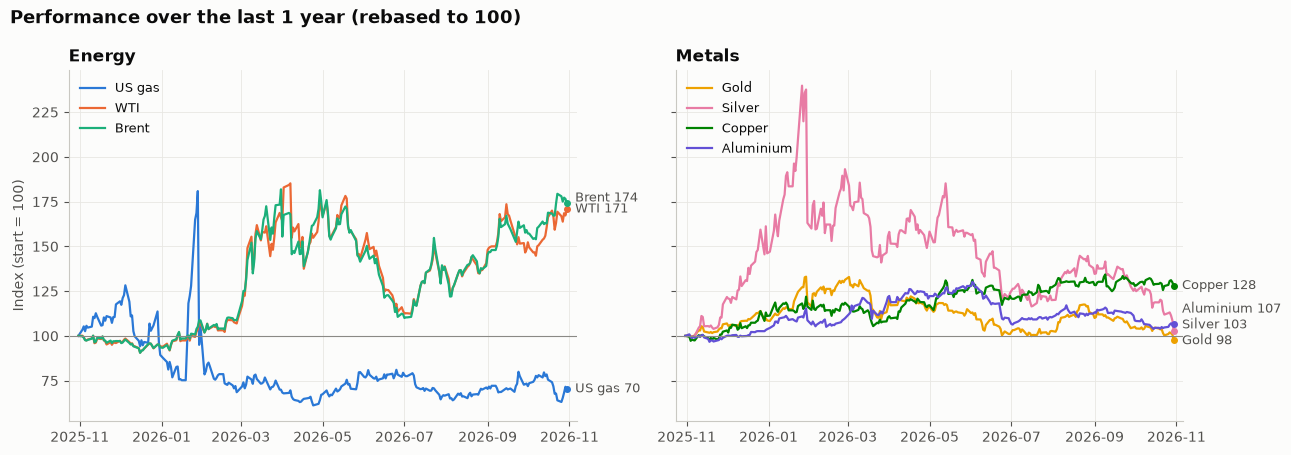

In [3]:
fig = plots.normalised_performance(daily, years=1)
plots.save(fig, "02_performance_1y")

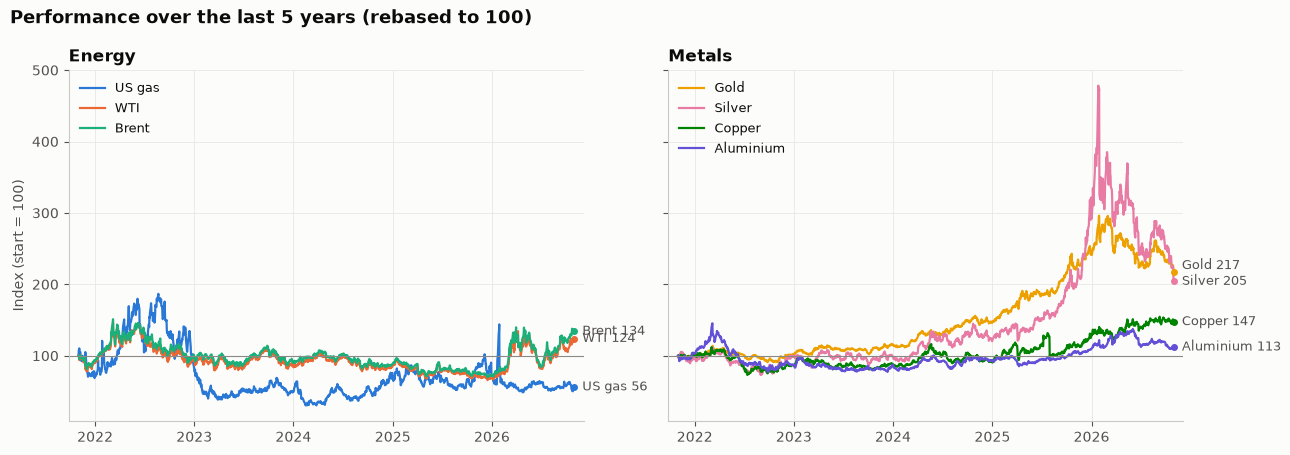

In [4]:
fig = plots.normalised_performance(daily, years=5)
plots.save(fig, "02_performance_5y")

## 3. Rolling volatility

Volatility is not constant. It clusters: calm periods and stormy periods each persist. A 3-month rolling window shows which regime each commodity is in now. **For sizing, today's vol matters more than the long-run average.**

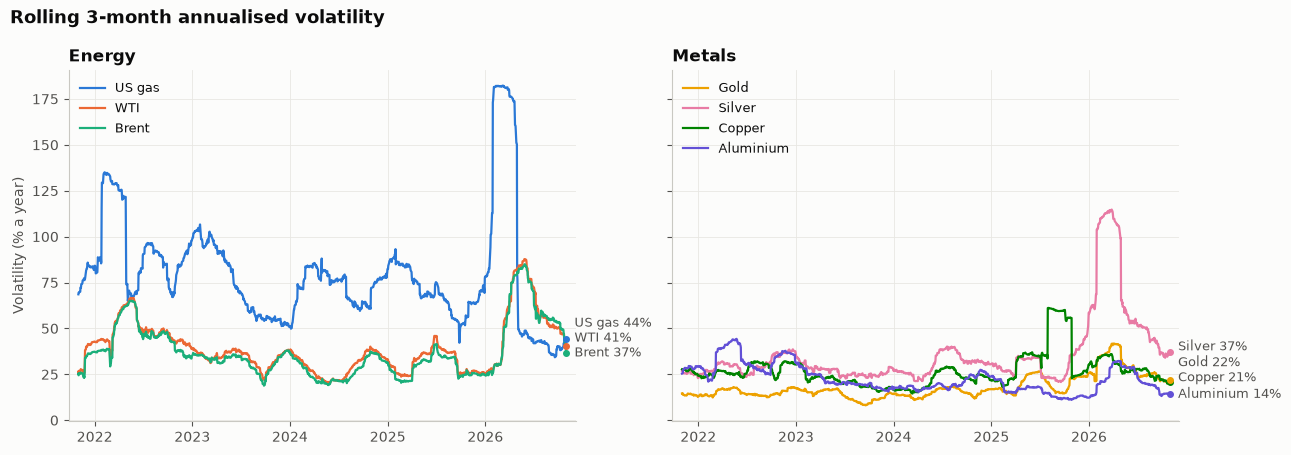

In [5]:
fig = plots.rolling_vol_chart(rolling_vol(daily, 63), years=5)
plots.save(fig, "02_rolling_vol")

**Reading it:**
- **The storm is calming.** Current 3-month vol is well below the 1-year figures in the table: gas about 45%, oil about 40%, silver under 40%, gold and copper around 20%, aluminium about 15%. Sizing off the 1-year number would make positions too small now. Sizing off today's number risks being caught when the regime flips back.
- **Flat-topped blocks are single days.** One huge return stays inside a 63-day window for exactly 63 days and then drops out, so it creates a plateau. Copper's 2025 block is the day the COMEX tariff premium collapsed, and gas's early-2026 block is the January expiry squeeze. An exponentially weighted vol (which a risk desk would use) fades such days gradually instead.
- **Gas vol is almost never below oil's peak vol.** Even gas's calm periods are as volatile as oil in a crisis.

## 4. Correlation: which positions are really the same bet?

Correlation of daily returns over the last 5 years. A pair near 1 moves together, so holding both doubles the bet rather than spreading it. A pair near 0 is genuinely different.

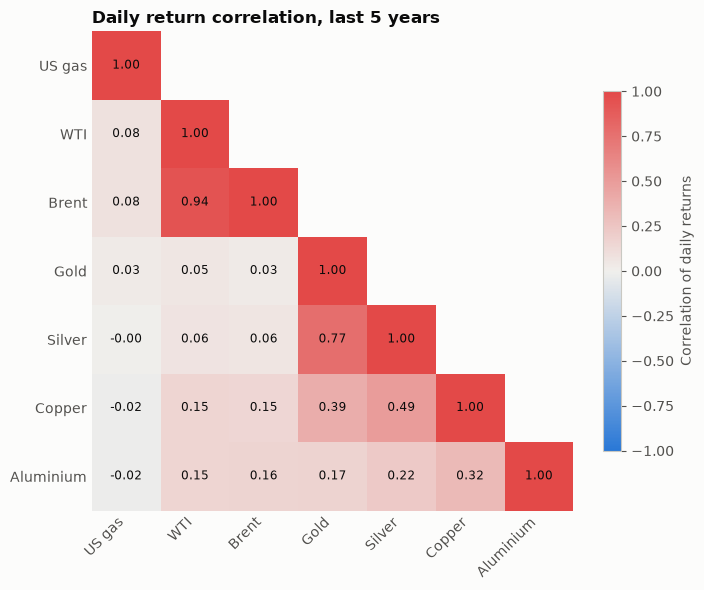

In [6]:
corr = return_correlation(daily, years=5)
corr.to_csv(TABLES_DIR / "02_correlation_5y.csv")
fig = plots.correlation_heatmap(corr, years=5)
plots.save(fig, "02_correlation")

**Reading the heatmap:**
- **WTI vs Brent ≈ 0.94.** Being long both is one oil position, not two. The interesting trade between them is the **spread** (Brent minus WTI), which reflects US export capacity and shipping, not the oil price itself.
- **Gold vs silver ≈ 0.77.** Silver behaves like leveraged gold, with about 2.5× the volatility this year.
- **Copper links metals together** (0.4–0.5 with gold and silver). Silver is roughly half an industrial metal, and copper is the macro "growth" metal.
- **Aluminium looks only loosely connected** (0.15–0.3). Part of that is real (aluminium is driven by power costs and Chinese smelter output), and part is the London vs New York timing mismatch from notebook 01, which pulls same-day correlations down.
- **US gas is uncorrelated with everything** (between −0.02 and 0.08), even oil. Henry Hub is a mostly landlocked North American market driven by US weather, storage and production. In a portfolio that makes it a genuine diversifier, but its risk comes from the weather, which no amount of macro reading will forecast.

## 5. Seasonality

Average month-on-month return by calendar month since 1990, from the World Bank monthly averages (1990 avoids the regulated-price era for US gas and gives about 36 years per month). A `*` marks a month whose average is significantly different from zero at p < 0.05.

**Three caveats before believing any seasonal pattern:**
1. **Multiple testing.** 12 months × 7 commodities = 84 tests. At p < 0.05, about **4 false positives** are expected from pure noise, and the heatmap shows 10. That's a little more than chance, which means some real seasonal effects are present, but any one starred cell could still be luck.
2. **Spot vs futures.** The World Bank gas series is a *spot* price. Gas spot is seasonal (winter demand), but the futures curve **already prices that in**: the January contract trades above the July contract all year. A CFD holder doesn't pocket the spot seasonal move. Instead, they pay or receive it at each monthly roll. **Seasonality you can see is usually seasonality you can't trade cheaply.**
3. **Averages hide dispersion.** A +3% average with a 55% hit rate is a coin toss with a slight tilt, not a signal. See the hit-rate table below.

Significant months: 10 of 84 tests (about 4 expected by chance)


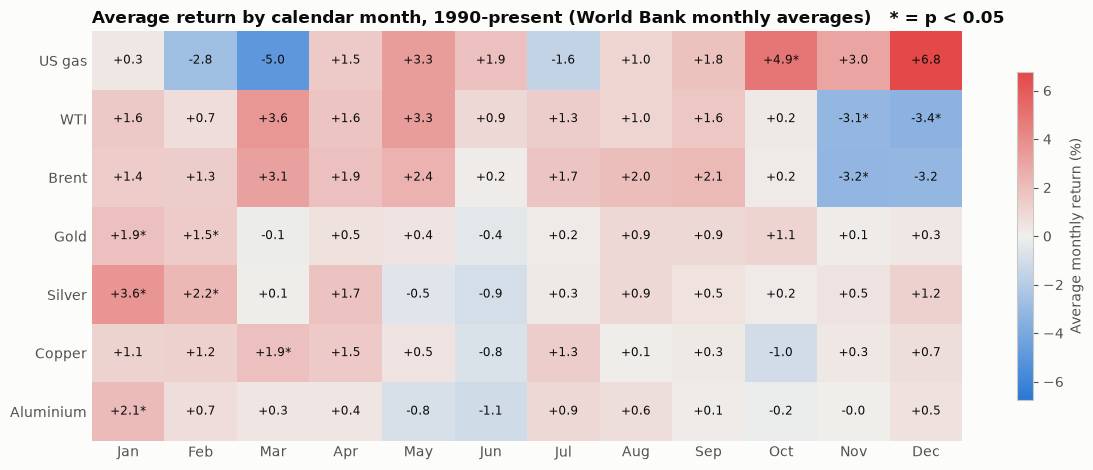

In [7]:
start = "1990"
mean_grid = seasonality_table(monthly, start, "mean")
p_grid = seasonality_table(monthly, start, "p_value")
fig = plots.seasonality_heatmap(mean_grid, p_grid, start)
plots.save(fig, "02_seasonality")
print(f"Significant months: {(p_grid < 0.05).sum().sum()} of {p_grid.size} tests "
      f"(about {0.05 * p_grid.size:.0f} expected by chance)")

In [8]:
hit = seasonality_table(monthly, start, "hit_rate")
hit.index = [SHORT_NAMES[c] for c in hit.index]
hit.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
hit.style.format("{:.0%}").background_gradient(cmap=plots.DIVERGING, vmin=0.2, vmax=0.8)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
US gas,42%,35%,38%,59%,65%,43%,38%,41%,57%,64%,50%,56%
WTI,69%,59%,57%,65%,54%,51%,62%,59%,54%,53%,36%,44%
Brent,67%,59%,59%,62%,51%,46%,59%,57%,62%,50%,33%,36%
Gold,69%,54%,46%,43%,38%,49%,43%,54%,51%,44%,53%,50%
Silver,67%,57%,41%,46%,41%,35%,41%,49%,41%,42%,44%,42%
Copper,67%,51%,62%,46%,54%,43%,65%,43%,54%,50%,56%,61%
Aluminium,61%,54%,49%,49%,46%,41%,68%,49%,51%,53%,44%,56%


In [9]:
seasonality(monthly["natgas_us"], start).style.format(
    {"mean": "{:+.1%}", "median": "{:+.1%}", "hit_rate": "{:.0%}", "t_stat": "{:.2f}", "p_value": "{:.3f}"})

,mean,median,hit_rate,n,t_stat,p_value
month,,,,,,
1,+0.3%,-0.5%,42%,36,0.08,0.940
2,-2.8%,-5.5%,35%,37,-0.65,0.522
3,-5.0%,-2.5%,38%,37,-1.96,0.058
4,+1.5%,+2.8%,59%,37,0.84,0.405
5,+3.3%,+1.2%,65%,37,1.89,0.067
6,+1.9%,-0.3%,43%,37,1.19,0.243
7,-1.6%,-1.7%,38%,37,-1.03,0.312
8,+1.0%,-2.5%,41%,37,0.50,0.617
9,+1.8%,+1.0%,57%,37,0.80,0.427


**What the seasonality says:**
- **US gas has the biggest calendar swings but almost no statistical certainty.** Spot prices tend to fall into March (end of winter: withdrawals stop and the heating premium fades) and rise from October to December (winter risk being priced in), which matches the storage project in `Energy/US_Gas_Storage`. Only October clears p < 0.05, though. Gas is so volatile that even a −5% average March is not distinguishable from noise across 36 years.
- **The late-January 2026 spike and crash in the 1-year chart** is the expiry squeeze flagged in notebook 01, and a reminder of what holding front-month gas through an expiry in a cold snap looks like.
- **Oil is consistently soft in November and December** (significant for WTI in both months, for Brent in November). Explanations often given: refinery maintenance and the end of the US driving season reduce crude demand, and producers hedge next year's output.
- **Metals lean positive early in the year.** Gold and silver are significant in January and February, aluminium in January and copper in March. Common explanations are Chinese restocking around Lunar New Year and Indian wedding-season gold demand. The effect is 1–4% a month, small next to their swings.
- **Overall: treat seasonality as a tiebreaker, not a strategy.** It can tell you when the wind usually blows, not whether to sail.

## 6. Screener takeaways

| | Vol tier | Trend now | Diversifies? | First impression for a leveraged CFD trader |
|---|---|---|---|---|
| US gas | Extreme | Down | Yes, vs everything | Moves can exceed margin quickly. Very small size only, and roll costs matter |
| WTI / Brent | High | Strong up | Not with each other | Pick one, not both. A trending market but crowded and headline-driven |
| Gold | Low–moderate | Down | Partly (vs energy) | The calmest and highest leverage allowed (20:1); correction underway |
| Silver | High | Down sharply | Not vs gold | Gold's high-beta cousin; harder to hold through swings |
| Copper | Moderate | Mixed | Partly | Good macro instrument; US tariff risk on COMEX |
| Aluminium | Low | Down | Mostly | Calm but niche; check whether a liquid CFD exists |

Notebook 03 turns these into a structured pros/cons scorecard.